In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / "src" / "custseg").exists():   # project root = folder that holds the package
    if ROOT == ROOT.parent:
        raise RuntimeError("run the notebook from inside the project folder")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
import pandas as pd, numpy as np
from IPython.display import Image, Markdown, display
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)
from custseg import config, db
img = lambda p, w=900: display(Image(filename=str(ROOT / p), width=w))

# 03 · Experiment 2 — RFM + K-Means

In [2]:
g = pd.read_csv(ROOT / '07_customer_segmentation/results/grid_results.csv')
g[g.experiment.str.startswith('E2')][['space','k','inertia','silhouette','davies_bouldin','calinski_harabasz','stability_seed_ari','stability_bootstrap_ari','min_cluster_share','interpretability']].round(3)

,space,k,inertia,silhouette,davies_bouldin,calinski_harabasz,stability_seed_ari,stability_bootstrap_ari,min_cluster_share,interpretability
0,rfm-original-standard,2,201150.496,0.736,0.550,36176.855,NaN,NaN,0.030,0.500
1,rfm-original-standard,3,137060.767,0.457,0.756,48313.359,1.000,0.999,0.030,0.833
2,rfm-original-standard,4,91526.288,0.489,0.681,63671.543,1.000,0.997,0.026,0.875
3,rfm-original-standard,5,76945.253,0.422,0.751,61212.907,0.995,0.880,0.025,0.800
4,rfm-original-standard,6,63099.521,0.438,0.702,63800.879,0.994,0.989,0.005,0.833
5,rfm-original-standard,7,53641.041,0.442,0.726,65277.435,0.993,0.992,0.002,0.714
6,rfm-original-standard,8,47813.190,0.449,0.719,64393.164,0.962,0.979,0.001,0.562
7,rfm-original-standard,9,43565.263,0.393,0.785,62971.349,NaN,NaN,0.002,0.500
8,rfm-original-standard,10,39359.679,0.395,0.747,63059.883,NaN,NaN,0.000,0.550
9,rfm-original-robust,2,197214.383,0.805,0.573,85510.921,NaN,NaN,0.036,0.500


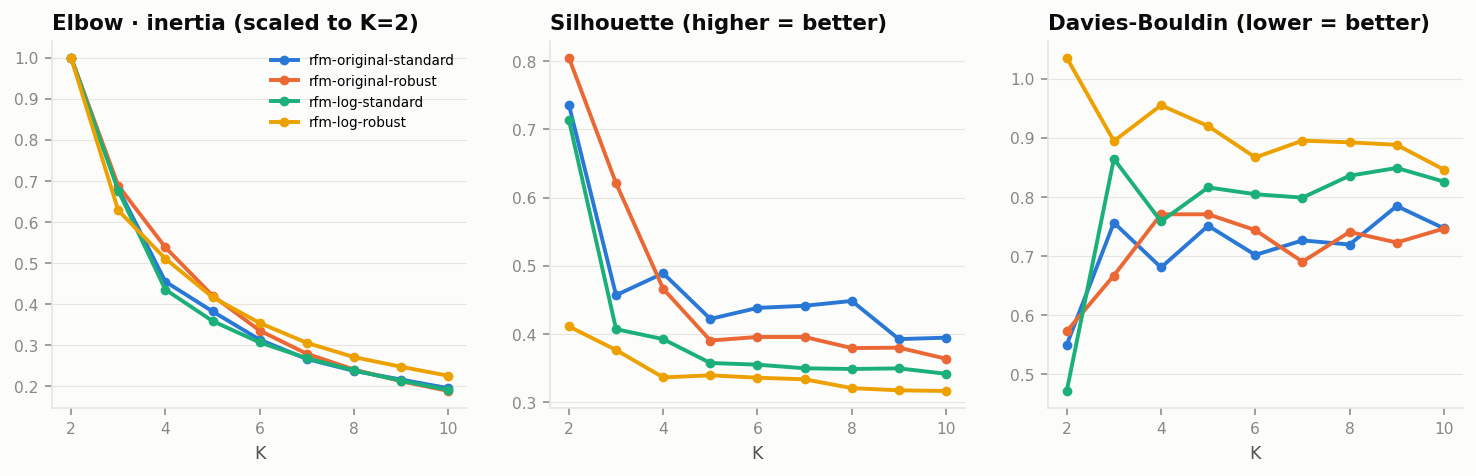

In [3]:
img('07_customer_segmentation/figures/e2_kmeans_k_selection.png')